In [54]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [55]:
df = pd.read_csv("train.csv")

In [56]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [57]:
df = pd.read_csv("train.csv", usecols=["Survived","Age","Fare"])

In [58]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [59]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [60]:
# fill the null value with replace mean of age column

df["Age"] = df["Age"].fillna(df["Age"].mean())

In [61]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [62]:
# extract the X and Y

X = df.iloc[:,1:3]
y = df.iloc[:,0]

In [63]:
x.head()

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500


In [64]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [65]:
# train test split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [66]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 2)
(179, 2)
(712,)
(179,)


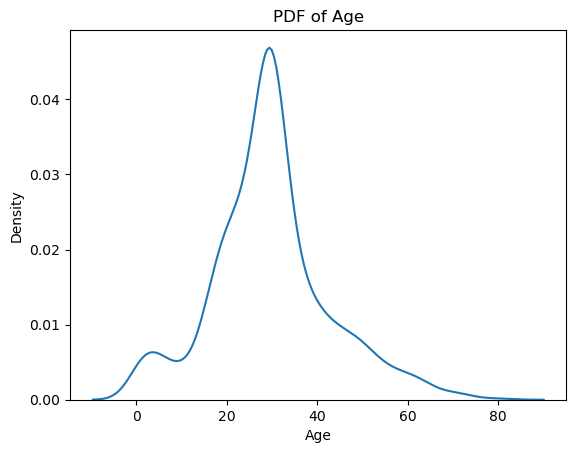

In [67]:
# check the PDF plot of Age Column

sns.kdeplot(x["Age"])
plt.title("PDF of Age")

plt.show()

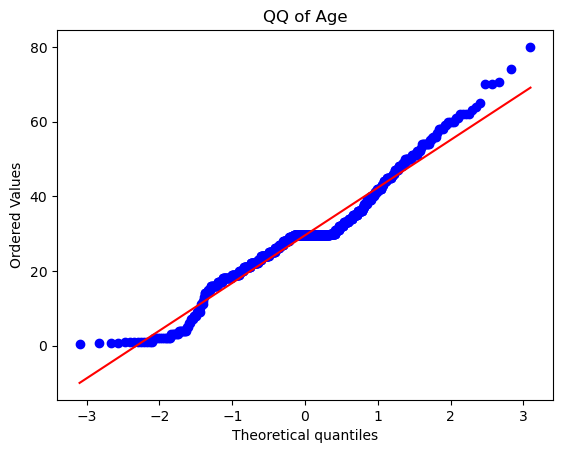

In [68]:
# check the QQ plot of Age Column

stats.probplot(X_train["Age"], dist="norm", plot=plt)
plt.title("QQ of Age")

plt.show()

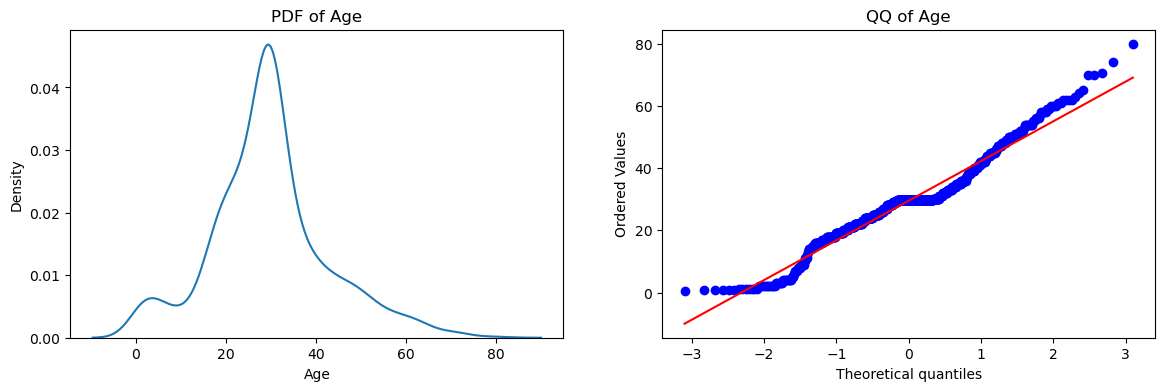

In [69]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.kdeplot(x["Age"])
plt.title("PDF of Age")

plt.subplot(122)
stats.probplot(X_train["Age"], dist="norm", plot=plt)
plt.title("QQ of Age")

plt.show()

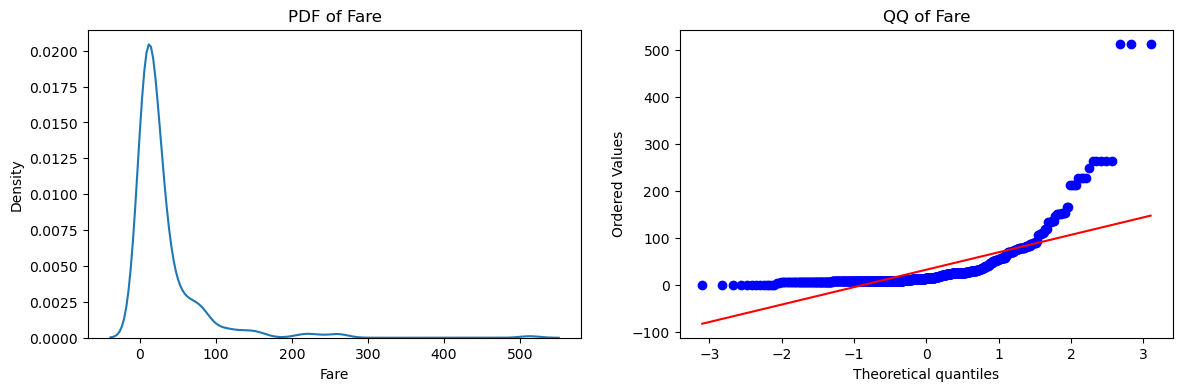

In [70]:
# same Fare Column Check

plt.figure(figsize=(14,4))
plt.subplot(121)
sns.kdeplot(x["Fare"])
plt.title("PDF of Fare")

plt.subplot(122)
stats.probplot(X_train["Fare"], dist="norm", plot=plt)
plt.title("QQ of Fare")

plt.show()

In [71]:
# first created the two objects of LogisticRegression and DecisionTreeClassifier

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [83]:
clf.fit(X_train,y_train)
clf2.fit(X_train, y_train)


y_pred = clf.predict(X_test)
y_pred2 = clf2.predict(X_test)


print("Accuracy of LR", accuracy_score(y_test, y_pred))
print("Accuracy of DT", accuracy_score(y_test, y_pred2))

Accuracy of LR 0.6480446927374302
Accuracy of DT 0.6703910614525139


## Apply the transformer - Log Transform

In [78]:
trf = FunctionTransformer(func=np.log1p)

In [84]:
X_train_transformed = trf.transform(X_train)
X_test_transformed  = trf.transform(X_test)

In [85]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [86]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)
    
y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6759776536312849


## Cross Validation

In [87]:
X_transformed = trf.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf,X_transformed,y,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,X_transformed,y,scoring='accuracy',cv=10)))

LR 0.678027465667915
DT 0.6599750312109862


### Check - Fare before QQ plot and Fare after QQ plot

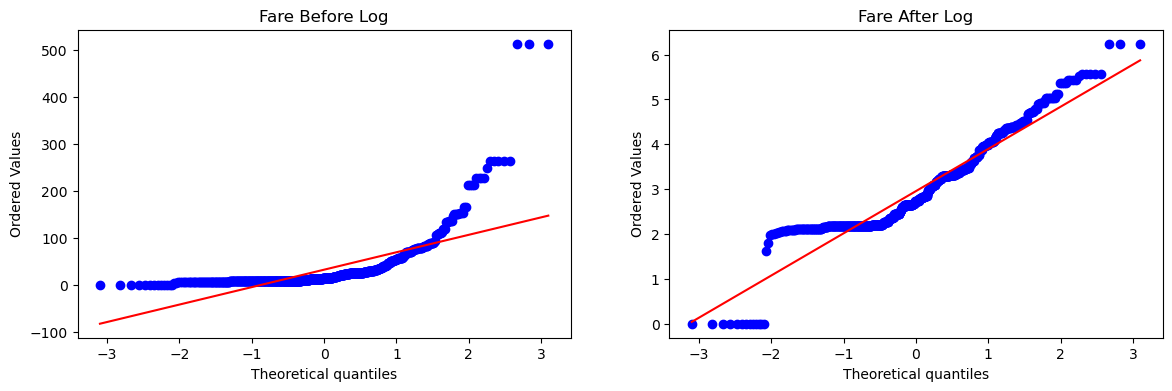

In [88]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist="norm", plot=plt)
plt.title('Fare After Log')

plt.show()

### Check - Age before QQ plot and Age after QQ plot

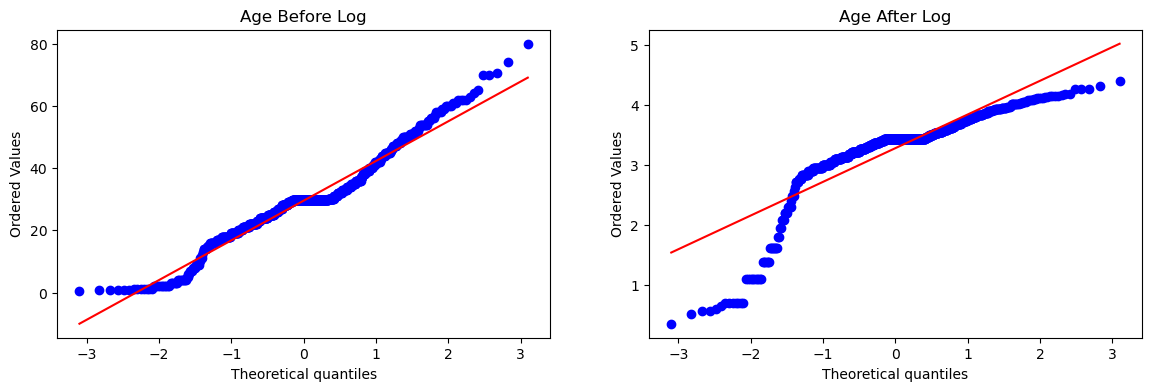

In [89]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'], dist="norm", plot=plt)
plt.title('Age Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist="norm", plot=plt)
plt.title('Age After Log')

plt.show()